# Kriging Interpolation with Boundary Masking

This notebook performs **Ordinary Kriging** spatial interpolation for Dissolved Oxygen (DO) data in the Seto Inland Sea.

Key features:
- Uses `pykrige` for Ordinary Kriging with a spherical variogram
- Derives a **water-only mask** by subtracting the land polygon from a station-bounds bounding box
- Interpolates only onto grid points that fall within the water area
- Maps results following the SIS mapping standard (Cartopy + custom boundary)
- Validates via **Leave-One-Out Cross-Validation (LOOCV)**

Reference: `18_interpolation_comparison_test.ipynb`

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import cartopy.crs as ccrs
from pathlib import Path
from shapely.geometry import box, Point
from pykrige.ok import OrdinaryKriging
import sys
import warnings
warnings.filterwarnings('ignore')

# Ensure local scripts are importable
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.paths import ProjectPaths

print(f"Project root: {project_root}")

Project root: /home/reyha/SIS_Analysis_WSL


## 1. Load Data

Load the yearly DO data, distance matrix, decorrelation scales, and station coordinates from the Summer/Bottom seasonal subset.

In [21]:
# --- Data Loading (matches 18_interpolation_comparison_test.ipynb) ---
subset_dir = str(ProjectPaths.get_subset_dir('Summer', 'bottom'))
subset_path = Path(subset_dir)

# 1. Yearly DO Data
yearly_do_df = pd.read_csv(subset_path / "yearly_do_df.csv", index_col=0)
yearly_do_df.index = yearly_do_df.index.astype(str).str.zfill(8)

# 2. Distance Matrix (km)
dist_matrix_km = pd.read_csv(ProjectPaths.PROCESSED_DATA_DIR / "dist_matrix_km.csv", index_col=0)
dist_matrix_km.index = dist_matrix_km.index.astype(str).str.zfill(8)
dist_matrix_km.columns = dist_matrix_km.columns.astype(str).str.zfill(8)

# 3. Decorrelation Scale Results
decorrelation_df = pd.read_csv(subset_path / "stations_decorrelation_scale.csv", index_col=0)
decorrelation_df.index = decorrelation_df.index.astype(str).str.zfill(8)

# 4. Station coordinates (projected to UTM Zone 53N for meter-based distances)
merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)
station_locs = merged_gdf.drop_duplicates('zettaicode').set_index('zettaicode')
station_locs = station_locs.loc[yearly_do_df.index]
station_locs_proj = station_locs.to_crs(epsg=32653)  # UTM Zone 53N
station_coords = pd.DataFrame({
    'x': station_locs_proj.geometry.x,
    'y': station_locs_proj.geometry.y
}, index=station_locs_proj.index)

# Also keep WGS84 coords for plotting
station_locs_wgs = station_locs.to_crs(epsg=4326)

print(f"Loaded Yearly DO Data: {yearly_do_df.shape}")
print(f"Number of stations: {len(station_coords)}")
print(f"Years available: {list(yearly_do_df.columns[:5])} ... {list(yearly_do_df.columns[-3:])}")

Loaded Yearly DO Data: (124, 41)
Number of stations: 124
Years available: ['1982', '1984', '1985', '1986', '1987'] ... ['2021', '2022', '2023']


## 2. Load Sea Area Mask & Build Interpolation Grid

Load the pre-computed sea area mask shapefile and generate a regular grid of interpolation points constrained to the water area.

In [22]:
# --- Load pre-computed sea area mask ---
sea_mask_path = ProjectPaths.BOUNDARIES_DIR / "SIS water mass polygon" / "sea_area_mask_simplified.shp"
sea_mask = gpd.read_file(sea_mask_path)

# Project to UTM 53N (same CRS as station coordinates)
sea_mask_proj = sea_mask.to_crs(epsg=32653)
water_polygon = sea_mask_proj.unary_union

print(f"Water polygon type: {water_polygon.geom_type}")
print(f"Water polygon area: {water_polygon.area / 1e6:.1f} km²")

# Generate regular grid within the water polygon bounds
grid_spacing = 1000  # 1 km resolution
wb = sea_mask_proj.total_bounds  # [minx, miny, maxx, maxy]
x_range = np.arange(wb[0], wb[2], grid_spacing)
y_range = np.arange(wb[1], wb[3], grid_spacing)
xx, yy = np.meshgrid(x_range, y_range)

# Flatten grid
grid_x_flat = xx.ravel()
grid_y_flat = yy.ravel()

# Filter: keep only points inside the water polygon
grid_points = gpd.GeoDataFrame(
    geometry=[Point(x, y) for x, y in zip(grid_x_flat, grid_y_flat)],
    crs='EPSG:32653'
)
water_mask = grid_points.within(water_polygon)
water_grid_x = grid_x_flat[water_mask.values]
water_grid_y = grid_y_flat[water_mask.values]

print(f"Total grid points: {len(grid_x_flat)}")
print(f"Water grid points: {len(water_grid_x)}")
print(f"Land points removed: {len(grid_x_flat) - len(water_grid_x)}")

Water polygon type: MultiPolygon
Water polygon area: 25563.3 km²
Total grid points: 105569
Water grid points: 25558
Land points removed: 80011


## 3. Kriging Interpolation (Single Year)

Perform Ordinary Kriging on a representative year to visualize the spatial DO distribution and kriging variance.

In [23]:
min_stations = 10
selected_year = "1991"  # Try 1991 first (use integer 1991 if columns are ints)

valid = yearly_do_df[selected_year].dropna()
valid_stations = list(set(valid.index) & set(station_coords.index))

# If 1991 doesn't have enough stations, search for one that does
if len(valid_stations) < min_stations:
    for year in yearly_do_df.columns:
        valid = yearly_do_df[year].dropna()
        valid_stations = list(set(valid.index) & set(station_coords.index))
        if len(valid_stations) >= min_stations:
            selected_year = year
            break

print(f"Selected year: {selected_year}")


# Extract valid station data for this year
year_data = yearly_do_df[selected_year].dropna()
valid_stations = list(set(year_data.index) & set(station_coords.index))
print(f"Valid stations: {len(valid_stations)}")

known_x = station_coords.loc[valid_stations, 'x'].values
known_y = station_coords.loc[valid_stations, 'y'].values
known_vals = year_data.loc[valid_stations].values

# --- Run Ordinary Kriging ---
# Convert to km to avoid float scaling issues in variogram fitting
ok_model = OrdinaryKriging(
    known_x / 1000.0,
    known_y / 1000.0,
    known_vals,
    variogram_model='spherical',
    verbose=False,
    enable_plotting=False
)

# Predict on the water-masked grid
z_pred, z_var = ok_model.execute(
    'points',
    water_grid_x / 1000.0,
    water_grid_y / 1000.0
)

z_pred = np.array(z_pred).ravel()
z_var = np.array(z_var).ravel()
z_std = np.sqrt(np.maximum(z_var, 0))  # Kriging standard deviation

print(f"Kriging complete for year {selected_year}")
print(f"  Predicted DO range: {z_pred.min():.2f} – {z_pred.max():.2f} mg/L")
print(f"  Kriging StdDev range: {z_std.min():.2f} – {z_std.max():.2f}")

Selected year: 1991
Valid stations: 124
Kriging complete for year 1991
  Predicted DO range: 3.77 – 7.00 mg/L
  Kriging StdDev range: 1.24 – 1.60


## 4. Visualize Kriging Results

Map the interpolated DO surface and kriging uncertainty, following the SIS mapping standard.

In [24]:
# --- Helper: convert UTM grid points back to WGS84 for plotting ---
grid_gdf = gpd.GeoDataFrame(
    {'z_pred': z_pred, 'z_std': z_std},
    geometry=[Point(x, y) for x, y in zip(water_grid_x, water_grid_y)],
    crs='EPSG:32653'
).to_crs(epsg=4326)

grid_lon = grid_gdf.geometry.x.values
grid_lat = grid_gdf.geometry.y.values

# Load land boundary for plotting (WGS84)
sis_boundary_wgs = sis_boundary.copy()
if sis_boundary_wgs.crs != 'EPSG:4326':
    sis_boundary_wgs = sis_boundary_wgs.to_crs('EPSG:4326')

# Station WGS84 coordinates for overlay
valid_locs_wgs = station_locs_wgs.loc[valid_stations]

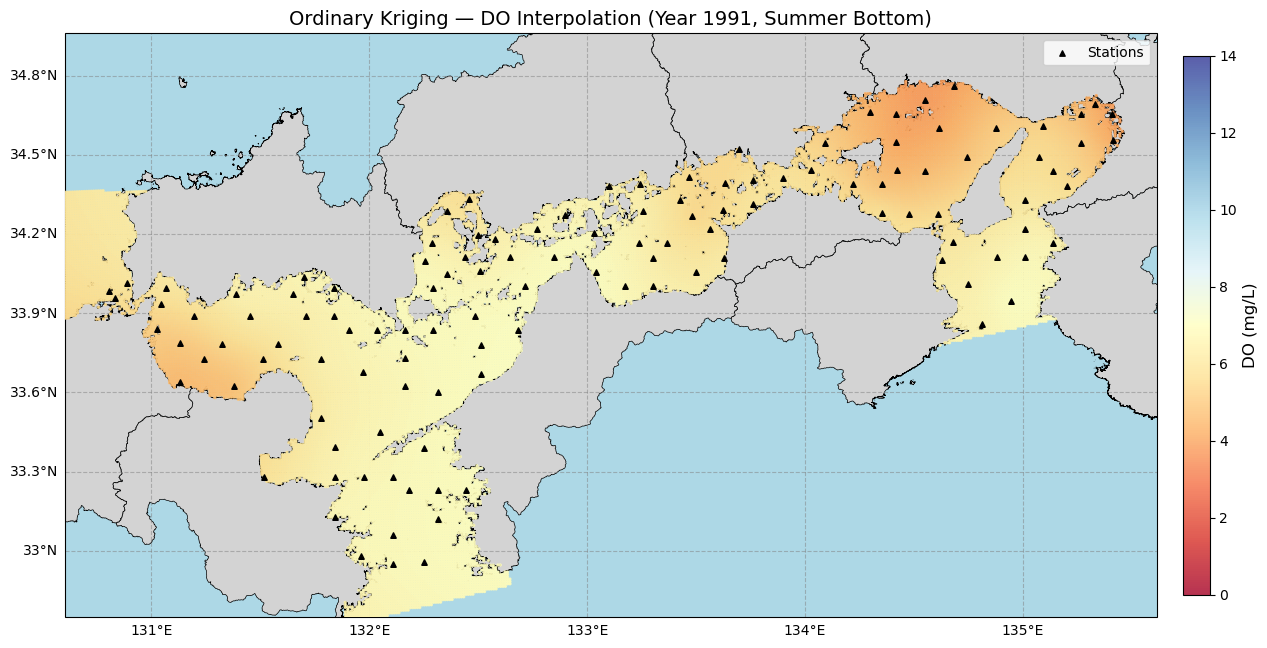

In [25]:
# --- Plot 1: Kriging DO Prediction ---
fig, ax = plt.subplots(figsize=(14, 8), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_facecolor('lightblue')

# Land
sis_boundary_wgs.plot(
    ax=ax, facecolor='lightgray', edgecolor='black', linewidth=0.5,
    transform=ccrs.PlateCarree(), zorder=1
)

# Kriging predictions
sc = ax.scatter(
    grid_lon, grid_lat, c=z_pred, s=2, cmap='RdYlBu',
    vmin=0.0, vmax=14.0,  # ← set your desired DO range here
    transform=ccrs.PlateCarree(), zorder=3, alpha=0.8
)

cbar = plt.colorbar(sc, ax=ax, shrink=0.7, pad=0.02)
cbar.set_label('DO (mg/L)', fontsize=12)

# Station locations
ax.scatter(
    valid_locs_wgs.geometry.x, valid_locs_wgs.geometry.y,
    c='black', s=15, marker='^', transform=ccrs.PlateCarree(),
    zorder=4, label='Stations'
)

# Gridlines
gl = ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.5, zorder=2)
gl.top_labels = False
gl.right_labels = False

# Extent
data_bounds = station_locs_wgs.total_bounds
ax.set_extent([
    data_bounds[0] - 0.2, data_bounds[2] + 0.2,
    data_bounds[1] - 0.2, data_bounds[3] + 0.2
], crs=ccrs.PlateCarree())

ax.set_title(f'Ordinary Kriging — DO Interpolation (Year {selected_year}, Summer Bottom)', fontsize=14)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

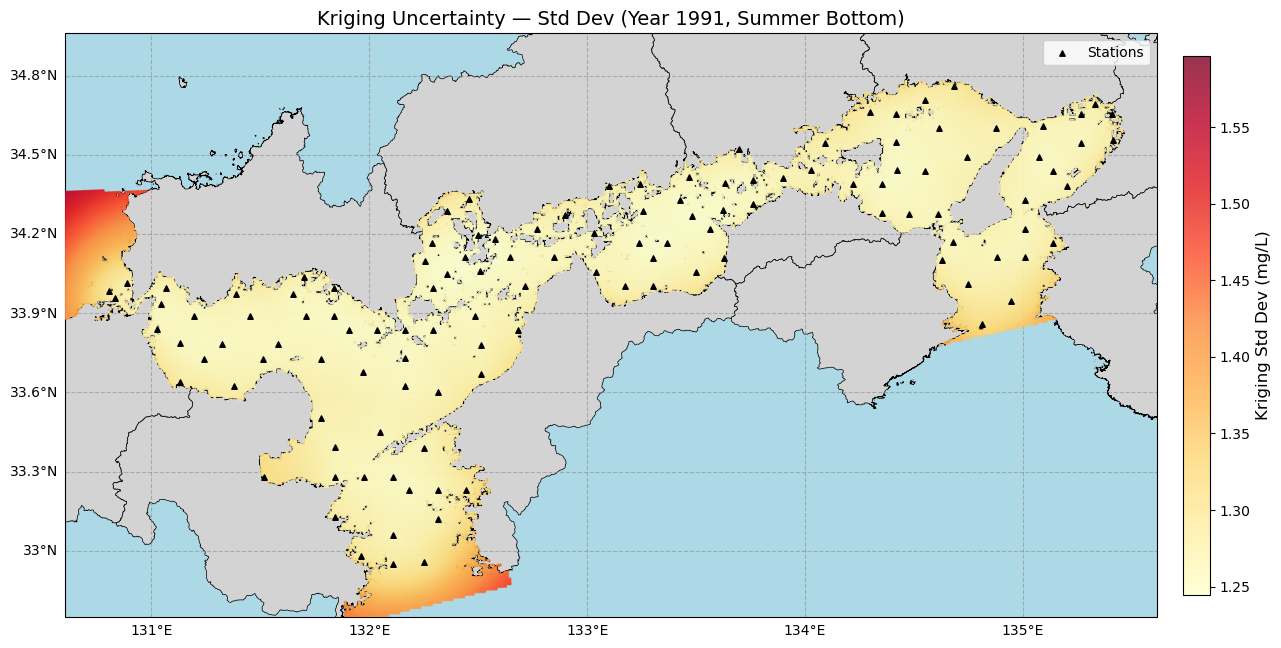

In [26]:
# --- Plot 2: Kriging Variance (Uncertainty) ---
fig, ax = plt.subplots(figsize=(14, 8), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_facecolor('lightblue')

# Land
sis_boundary_wgs.plot(
    ax=ax, facecolor='lightgray', edgecolor='black', linewidth=0.5,
    transform=ccrs.PlateCarree(), zorder=1
)

# Kriging standard deviation
sc = ax.scatter(
    grid_lon, grid_lat, c=z_std, s=2, cmap='YlOrRd',
    transform=ccrs.PlateCarree(), zorder=3, alpha=0.8
)
cbar = plt.colorbar(sc, ax=ax, shrink=0.7, pad=0.02)
cbar.set_label('Kriging Std Dev (mg/L)', fontsize=12)

# Station locations
ax.scatter(
    valid_locs_wgs.geometry.x, valid_locs_wgs.geometry.y,
    c='black', s=15, marker='^', transform=ccrs.PlateCarree(),
    zorder=4, label='Stations'
)

# Gridlines
gl = ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.5, zorder=2)
gl.top_labels = False
gl.right_labels = False

# Extent
ax.set_extent([
    data_bounds[0] - 0.2, data_bounds[2] + 0.2,
    data_bounds[1] - 0.2, data_bounds[3] + 0.2
], crs=ccrs.PlateCarree())

ax.set_title(f'Kriging Uncertainty — Std Dev (Year {selected_year}, Summer Bottom)', fontsize=14)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 5. Leave-One-Out Cross-Validation (LOOCV)

Validate the kriging interpolation by iteratively removing one station and predicting its value from the remaining stations. This follows the same approach as `18_interpolation_comparison_test.ipynb`.

In [27]:
# --- LOOCV ---
results = []
years_to_process = yearly_do_df.columns[:5]  # First 5 years for speed

for year in years_to_process:
    year_data = yearly_do_df[year].dropna()
    valid_stations = list(set(year_data.index) & set(station_coords.index))
    
    if len(valid_stations) < min_stations:
        continue
    
    print(f"Processing Year: {year} ({len(valid_stations)} stations)")
    
    for target_station in valid_stations:
        true_val = year_data.loc[target_station]
        target_loc = station_coords.loc[target_station].values
        
        # Training data (all except target)
        train_stations = [s for s in valid_stations if s != target_station]
        train_x = station_coords.loc[train_stations, 'x'].values
        train_y = station_coords.loc[train_stations, 'y'].values
        train_vals = year_data.loc[train_stations].values
        
        # Kriging prediction at the held-out station
        try:
            ok = OrdinaryKriging(
                train_x / 1000.0,
                train_y / 1000.0,
                train_vals,
                variogram_model='spherical',
                verbose=False,
                enable_plotting=False
            )
            z, _ = ok.execute(
                'points',
                np.array([target_loc[0] / 1000.0]),
                np.array([target_loc[1] / 1000.0])
            )
            pred_val = float(np.array(z).ravel()[0])
        except Exception:
            pred_val = np.nan
        
        results.append({
            'Year': year,
            'Station': target_station,
            'True_DO': true_val,
            'Pred_KG': pred_val
        })

loocv_results = pd.DataFrame(results)
print(f"\nFinished LOOCV. Total predictions: {len(loocv_results)}")

Processing Year: 1982 (124 stations)
Processing Year: 1984 (124 stations)
Processing Year: 1985 (124 stations)
Processing Year: 1986 (124 stations)
Processing Year: 1987 (122 stations)

Finished LOOCV. Total predictions: 618


## 6. LOOCV Results

Compute error metrics and visualize predicted vs. true DO.

,MAE,RMSE,Valid_N
Method,,,
Kriging,0.614399,0.925108,618


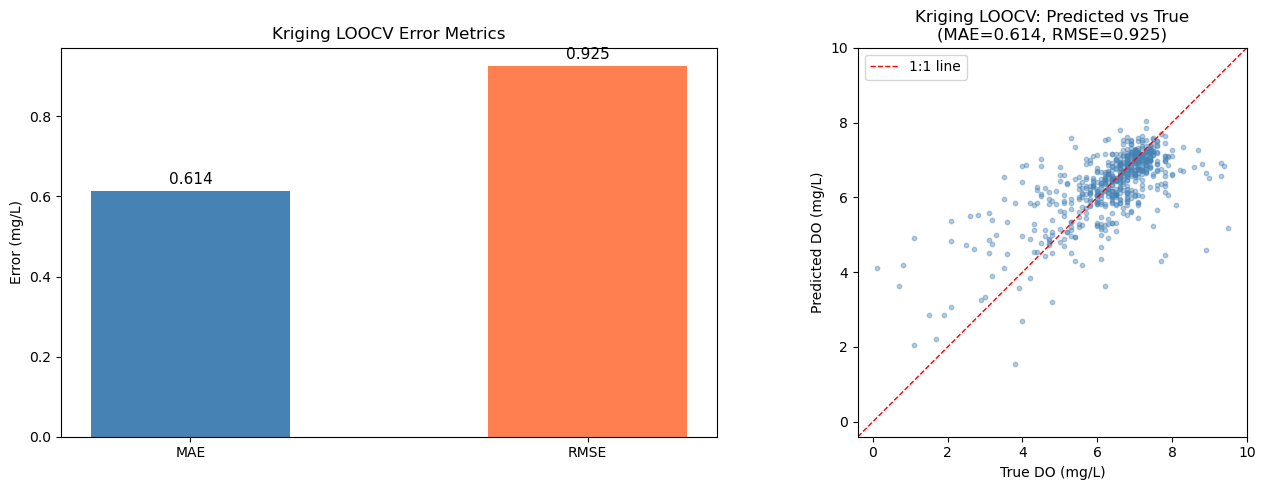

In [28]:
# --- Compute MAE and RMSE ---
valid_results = loocv_results.dropna(subset=['Pred_KG'])
errors = valid_results['Pred_KG'] - valid_results['True_DO']
mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors**2))

metrics = pd.DataFrame({
    'MAE': [mae],
    'RMSE': [rmse],
    'Valid_N': [len(valid_results)]
}, index=['Kriging'])
metrics.index.name = 'Method'

display(metrics)

# --- Scatter plot: Predicted vs True ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart of metrics
ax = axes[0]
x_pos = [0, 1]
bars = ax.bar(x_pos, [mae, rmse], color=['steelblue', 'coral'], width=0.5)
ax.set_xticks(x_pos)
ax.set_xticklabels(['MAE', 'RMSE'])
ax.set_ylabel('Error (mg/L)')
ax.set_title('Kriging LOOCV Error Metrics')
for b, val in zip(bars, [mae, rmse]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
            f'{val:.3f}', ha='center', va='bottom', fontsize=11)

# Scatter plot
ax = axes[1]
ax.scatter(valid_results['True_DO'], valid_results['Pred_KG'],
           alpha=0.4, s=10, color='steelblue')
lims = [
    min(valid_results['True_DO'].min(), valid_results['Pred_KG'].min()) - 0.5,
    max(valid_results['True_DO'].max(), valid_results['Pred_KG'].max()) + 0.5
]
ax.plot(lims, lims, 'r--', linewidth=1, label='1:1 line')
ax.set_xlabel('True DO (mg/L)')
ax.set_ylabel('Predicted DO (mg/L)')
ax.set_title(f'Kriging LOOCV: Predicted vs True\n(MAE={mae:.3f}, RMSE={rmse:.3f})')
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.legend()
ax.set_aspect('equal')

plt.tight_layout()
plt.show()

## Conclusions

This notebook demonstrates Ordinary Kriging interpolation with boundary masking:

- The **water-only mask** (derived by subtracting the land polygon from the station bounding box) ensures interpolation is constrained to physically meaningful areas
- The **kriging variance map** highlights regions with higher uncertainty, typically far from observation stations
- **LOOCV validation** provides quantitative assessment of kriging prediction accuracy

These results can be compared with the other interpolation methods evaluated in `18_interpolation_comparison_test.ipynb`.